# Systemic risk measures and backtesting

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Individual risk measures

### Value at risk(VaR)

#### Historical Simulation

The VaR at the $\alpha\%$ level is the $\alpha\%$ quantile of the return distribution $(F)$:

$$
VaR_{t}(\alpha) = F^{-1}_{r_{t}}(\alpha)
$$

In [2]:
#Data import
df_ret_asset = pd.read_csv('ret_asset.csv')
df_ret_asset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 753 entries, 0 to 752
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    753 non-null    object 
 1   ALL     753 non-null    float64
 2   PNC     753 non-null    float64
 3   MBI     753 non-null    float64
 4   AIG     753 non-null    float64
 5   HIG     753 non-null    float64
 6   UNM     753 non-null    float64
 7   HUM     753 non-null    float64
 8   KEY     753 non-null    float64
 9   CINF    753 non-null    float64
 10  GS      753 non-null    float64
 11  UNH     753 non-null    float64
 12  BK      753 non-null    float64
 13  NTRS    753 non-null    float64
 14  PGR     753 non-null    float64
 15  AXP     753 non-null    float64
 16  SEIC    753 non-null    float64
 17  FITB    753 non-null    float64
 18  ZION    753 non-null    float64
 19  CNA     753 non-null    float64
 20  BEN     753 non-null    float64
dtypes: float64(20), object(1)
memory usage:

In [3]:
df_ret_asset['Date'] = pd.to_datetime(df_ret_asset['Date'])
df_ret_asset.set_index('Date', inplace = True)
df_ret_asset

,ALL,PNC,MBI,AIG,HIG,UNM,HUM,KEY,CINF,GS,UNH,BK,NTRS,PGR,AXP,SEIC,FITB,ZION,CNA,BEN
Date,,,,,,,,,,,,,,,,,,,,
2021-01-04,-1.697209,0.100616,-2.617549,-1.946986,-1.418752,-3.775711,0.466896,-0.733942,-3.340047,0.487984,-0.337054,-1.783002,-0.689509,-1.785671,-2.402294,-0.944065,-1.240892,-1.180975,-2.442311,-2.635464
2021-01-05,-0.789562,-0.531071,2.769412,1.656018,-0.664868,0.811548,0.239890,1.583458,-0.951259,2.213063,-1.353906,1.121064,-0.748745,-0.185491,0.532296,0.455659,1.385876,1.571561,0.603121,-0.246810
2021-01-06,2.541334,5.347811,8.713781,6.313023,5.850093,6.392088,5.794736,9.283531,4.599857,5.255664,4.110966,6.541275,5.797502,1.880104,3.632551,6.923768,9.164866,10.648343,5.369565,5.020126
2021-01-07,0.072709,1.578433,-1.118892,1.676982,-0.908557,-0.931024,2.227036,1.800867,0.045632,2.113733,1.590537,0.598076,0.297635,0.555189,-0.791351,0.195597,3.825427,3.005309,-0.223242,-0.156805
2021-01-08,-0.109084,-0.510734,3.591543,-0.662499,-1.017064,-0.768251,-2.469432,-1.361306,0.113984,-0.539773,-0.450286,-1.065728,-0.709626,-0.253644,0.098583,0.649250,-0.830411,-2.573337,-1.375192,-0.827261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,1.466302,0.460162,3.514164,0.539328,0.630360,0.378995,-0.163148,0.070005,0.000000,0.021015,0.082676,0.136094,0.047713,0.814668,0.421220,0.248018,0.203281,0.867390,0.285916,0.506335
2023-12-26,0.493691,1.063392,3.326714,0.298370,0.288641,0.355398,-0.081681,1.113441,0.684939,0.251880,-0.053822,0.966752,0.487839,-0.241156,0.209942,-0.015475,1.411511,1.980265,-0.023791,1.271342
2023-12-27,0.224254,0.582333,-8.605780,0.029795,0.212804,0.177231,-0.311855,0.483264,0.194834,0.749269,0.529325,0.192231,0.379102,0.177754,0.589778,0.000001,0.314153,-0.827844,-0.381497,0.331897


In [4]:
alpha = 0.05
df_ret_asset.quantile(alpha)

ALL    -2.249221
PNC    -2.931314
MBI    -4.829746
AIG    -3.060443
HIG    -2.394727
UNM    -3.196311
HUM    -2.482824
KEY    -3.798497
CINF   -2.450966
GS     -2.472720
UNH    -2.203455
BK     -2.655114
NTRS   -3.139406
PGR    -2.205042
AXP    -2.838759
SEIC   -2.335234
FITB   -3.450329
ZION   -4.116127
CNA    -2.321932
BEN    -3.289422
Name: 0.05, dtype: float64

#### Rolling window historical VaR

In [5]:
def rolling_var_historical(series, alpha=0.05, window=250):
    return series.rolling(window).quantile(alpha)

rolling_var = rolling_var_historical(df_ret_asset, alpha=0.05, window=250)
rolling_var

,ALL,PNC,MBI,AIG,HIG,UNM,HUM,KEY,CINF,GS,UNH,BK,NTRS,PGR,AXP,SEIC,FITB,ZION,CNA,BEN
Date,,,,,,,,,,,,,,,,,,,,
2021-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,-2.503481,-2.932185,-3.988179,-2.62552,-2.112131,-2.470243,-2.778209,-4.855758,-2.226555,-2.271914,-1.886793,-2.131899,-2.688562,-1.963234,-2.52052,-1.784228,-3.628244,-5.515923,-2.101002,-2.806669
2023-12-26,-2.503481,-2.932185,-3.988179,-2.62552,-2.112131,-2.470243,-2.778209,-4.855758,-2.226555,-2.271914,-1.886793,-2.131899,-2.688562,-1.963234,-2.52052,-1.784228,-3.628244,-5.515923,-2.101002,-2.806669
2023-12-27,-2.503481,-2.932185,-4.007795,-2.62552,-2.112131,-2.470243,-2.778209,-4.855758,-2.226555,-2.271914,-1.886793,-2.131899,-2.688562,-1.963234,-2.52052,-1.784228,-3.628244,-5.515923,-2.101002,-2.779032


#### Predicted VaR

$$ 
VaR^\alpha_{i, t+1 \mid t} = \sigma_{i, t+1 \mid t} \times q_{\alpha,t}
$$

where $\sigma_{i, t+1 \mid t}$ can be calculated based on Garch and $q_{\alpha,t} = F^{-1}_{\alpha} \left( { z_{i, t} } \right)$ is the conditional empirical $\alpha$-quantile of the standardized residuals $z_{i, t} = \frac{r_{i, t}}{\sigma_{i, t}}$.

In [6]:
from arch import arch_model

In [7]:
def compute_var(df_ret, window = 250, alpha = 0.05):

    # Create output DataFrames with same shape/index/columns
    df_Vol = pd.DataFrame(np.nan, index=df_ret.index, columns=df_ret.columns)
    df_Q05 = pd.DataFrame(np.nan, index=df_ret.index, columns=df_ret.columns)
    df_VaR = pd.DataFrame(np.nan, index=df_ret.index, columns=df_ret.columns)

    for col in df_ret.columns:
        col_idx = df_ret.columns.get_loc(col) + 1
        for j in range(window, len(df_ret[col])):
            
            # Slice the rolling window for the current asset.
            rolling_data = df_ret[col][j-window:j]

            # Fit GARCH(1,1) with Zero mean and normal distribution
            garch_model = arch_model(rolling_data, mean='Zero', vol='GARCH',p=1, q=1,dist='normal').fit(disp='off')

            # forecast(horizon=1).variance is σ^2，you MUST take the square root to get σ.
            sigma_forecast = np.sqrt(garch_model.forecast(horizon=1).variance.values[0, 0])

            # In-window conditional volatility σ_t and standardized residuals z_t
            sigma_in = garch_model.conditional_volatility.values  # σ_t for the window
            print(sigma_in)
            z = rolling_data / sigma_in  # equivalent to garch_model.std_resid
            if j ==window:
                # print(rolling_data)
                # print(len(sigma_in), len(rolling_data))
                pass

            # Empirical alpha-quantile within window
            q_alpha = np.quantile(z, alpha)

            # Save the results
            df_Vol.iloc[j, df_Vol.columns.get_loc(col)] = sigma_forecast
            df_Q05.iloc[j, df_Q05.columns.get_loc(col)] = q_alpha
            df_VaR.iloc[j, df_VaR.columns.get_loc(col)] = sigma_forecast * q_alpha

            # Print the row and column we are running
            # print(f"Processing row {j+1}/{len(df_ret)}, column {col_idx}/{len(df_ret.columns)}")

    return df_VaR, df_Vol, df_Q05

In [ ]:
df_VaR_asset, df_Vol_asset, df_Q05 = compute_var(df_ret_asset)

[1.23618258 1.23690407 1.23762514 1.2383458  1.23906603 1.23978584
 1.24050524 1.24122422 1.24194278 1.24266093 1.24337866 1.24409598
 1.24481289 1.24552938 1.24624546 1.24696113 1.24767639 1.24839124
 1.24910568 1.24981972 1.25053334 1.25124656 1.25195937 1.25267178
 1.25338378 1.25409537 1.25480657 1.25551736 1.25622775 1.25693773
 1.25764732 1.2583565  1.25906529 1.25977368 1.26048167 1.26118926
 1.26189645 1.26260325 1.26330965 1.26401566 1.26472128 1.2654265
 1.26613133 1.26683576 1.26753981 1.26824346 1.26894672 1.2696496
 1.27035208 1.27105418 1.27175589 1.27245721 1.27315815 1.2738587
 1.27455886 1.27525865 1.27595804 1.27665706 1.27735569 1.27805394
 1.27875181 1.27944929 1.2801464  1.28084313 1.28153948 1.28223545
 1.28293104 1.28362626 1.2843211  1.28501556 1.28570965 1.28640337
 1.28709671 1.28778968 1.28848227 1.2891745  1.28986635 1.29055783
 1.29124894 1.29193968 1.29263005 1.29332005 1.29400969 1.29469896
 1.29538786 1.29607639 1.29676456 1.29745237 1.29813981 1.2988268

C:\Users\mateo\AppData\Local\Temp\ipykernel_27888\1785097022.py:16: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  garch_model = arch_model(rolling_data, mean='Zero', vol='GARCH',p=1, q=1,dist='normal').fit(disp='off')


[1.54149233 1.54936604 1.55692106 1.5641719  1.5711323  1.57781522
 1.58423295 1.59039713 1.59631879 1.6020084  1.60747589 1.61273072
 1.61778188 1.62263786 1.62730682 1.63179652 1.63611432 1.64026727
 1.64426211 1.6481052  1.65180267 1.65536037 1.65878388 1.66207854
 1.66524945 1.6683015  1.67123936 1.67406748 1.67679017 1.6794115
 1.68193543 1.68436571 1.68670594 1.68895958 1.69112995 1.69322024
 1.69523349 1.69717263 1.69904047 1.70083972 1.70257296 1.70424267
 1.70585125 1.70740099 1.7088941  1.71033269 1.71171879 1.71305437
 1.7143413  1.71558139 1.71677638 1.71792793 1.71903766 1.72010711
 1.72113777 1.72213106 1.72308836 1.724011   1.72490024 1.72575732
 1.7265834  1.72737963 1.72814711 1.72888686 1.72959992 1.73028726
 1.73094981 1.73158847 1.73220413 1.7327976  1.7333697  1.73392121
 1.73445287 1.7349654  1.7354595  1.73593583 1.73639504 1.73683775
 1.73726455 1.73767602 1.73807272 1.73845517 1.73882389 1.73917939
 1.73952212 1.73985256 1.74017116 1.74047832 1.74077448 1.74106

C:\Users\mateo\AppData\Local\Temp\ipykernel_27888\1785097022.py:16: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  garch_model = arch_model(rolling_data, mean='Zero', vol='GARCH',p=1, q=1,dist='normal').fit(disp='off')


[1.69910279 1.71352509 1.72740345 1.74076333 1.75362865 1.76602182
 1.77796386 1.78947461 1.80057273 1.81127584 1.82160055 1.83156262
 1.84117693 1.85045758 1.85941797 1.86807085 1.87642827 1.88450172
 1.89230217 1.89984011 1.90712535 1.91416744 1.92097548 1.92755805
 1.93392346 1.94007962 1.94603412 1.95179416 1.95736672 1.96275845
 1.96797574 1.97302468 1.97791136 1.98264103 1.98721927 1.99165133
 1.99594217 2.00009665 2.00411944 2.0080148  2.01178712 2.01544054
 2.01897895 2.02240622 2.02572608 2.02894198 2.03205739 2.03507559
 2.03799977 2.04083312 2.04357835 2.0462384  2.04881606 2.05131402
 2.05373476 2.05608076 2.05835444 2.06055814 2.06269404 2.06476431
 2.06677103 2.06871622 2.07060182 2.07242971 2.07420172 2.07591956
 2.07758498 2.07919958 2.08076497 2.0822827  2.08375422 2.085181
 2.08656442 2.08790582 2.0892065  2.09046776 2.09169076 2.09287675
 2.09402679 2.09514204 2.09622355 2.09727237 2.09829008 2.09927648
 2.1002331  2.10116095 2.10206072 2.10293337 2.10377972 2.104600

C:\Users\mateo\AppData\Local\Temp\ipykernel_27888\1785097022.py:16: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  garch_model = arch_model(rolling_data, mean='Zero', vol='GARCH',p=1, q=1,dist='normal').fit(disp='off')


[1.24423685 1.27746814 1.30866857 1.33802348 1.3656924  1.39181446
 1.41651163 1.43989168 1.46205053 1.48307393 1.503039   1.52201544
 1.54006645 1.55724981 1.57361791 1.58921894 1.60409742 1.6182943
 1.63184742 1.64479204 1.65716051 1.6689832  1.68028832 1.69110228
 1.70144993 1.71135499 1.72083771 1.72991927 1.73861887 1.74695458
 1.75494345 1.76260165 1.76994411 1.77698532 1.78373886 1.79021759
 1.79643375 1.80239891 1.80812399 1.81361945 1.81889532 1.8239608
 1.82882499 1.8334964  1.83798316 1.84229303 1.8464334  1.85041131
 1.85423353 1.8579064  1.86143604 1.86482851 1.86808905 1.87122319
 1.87423603 1.87713248 1.87991717 1.88259459 1.88516908 1.88764533
 1.89002683 1.89231679 1.89451857 1.89663609 1.89867295 1.90063196
 1.90251642 1.90432906 1.90607281 1.90775033 1.90936414 1.91091675
 1.91241059 1.91384782 1.91523073 1.9165613  1.91784164 1.9190736
 1.92025908 1.92140132 1.92249914 1.92355563 1.92457224 1.92555061
 1.9264922  1.92739841 1.9282706  1.92911    1.9299179  1.9306954

### VaR backtesting

In [24]:
df_VaR_asset_bt = df_VaR_asset.iloc[250:]
df_VaR_asset_bt

,ALL,PNC,MBI,AIG,HIG,UNM,HUM,KEY,CINF,GS,UNH,BK,NTRS,PGR,AXP,SEIC,FITB,ZION,CNA,BEN
Date,,,,,,,,,,,,,,,,,,,,
2021-12-30,-2.034847,-2.331850,-4.462134,-2.256389,-1.856351,-3.248268,-1.822304,-2.600563,-2.229729,-2.385930,-1.699388,-2.338975,-2.454635,-1.974310,-2.370211,-2.402016,-2.668201,-3.287403,-1.940129,-3.362967
2021-12-31,-2.053905,-2.308766,-3.914222,-2.169157,-1.761352,-3.194809,-1.806752,-2.624653,-2.200445,-2.390580,-1.699763,-2.346444,-2.366397,-1.986890,-2.339184,-2.358683,-2.501245,-3.311123,-1.976918,-3.347611
2022-01-03,-2.040607,-2.293719,-14.413319,-2.113323,-1.618721,-3.336613,-1.806752,-2.642416,-2.201684,-2.394411,-1.700003,-2.356186,-2.294893,-1.946451,-2.315005,-2.508096,-2.367893,-3.127118,-1.842910,-3.322073
2022-01-04,-1.898933,-3.133041,-10.156814,-2.167630,-1.616197,-3.517557,-1.946456,-2.977269,-2.196565,-2.629137,-1.700593,-2.328995,-2.271546,-1.960101,-2.598582,-2.359998,-2.853742,-3.201878,-2.002057,-3.301427
2022-01-05,-1.898060,-3.479549,-6.875023,-2.741677,-2.206601,-3.620447,-1.951858,-4.435263,-2.199607,-2.677698,-1.766606,-2.347832,-2.721739,-1.923241,-2.836984,-2.617133,-3.787787,-3.485871,-2.374141,-3.411285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,-2.378856,-3.238265,-6.413066,-1.957432,-1.872828,-2.208204,-2.813940,-4.077633,-1.757066,-2.273835,-1.896651,-1.853837,-2.783058,-2.491483,-2.059010,-1.915745,-3.773796,-5.392770,-1.695887,-2.791241
2023-12-26,-2.494503,-2.962967,-6.478538,-1.856948,-1.817146,-2.171657,-2.800024,-3.625922,-1.720371,-2.147688,-1.877500,-1.764407,-2.702166,-2.470225,-2.043904,-1.697808,-3.298152,-4.705570,-1.600525,-2.697574
2023-12-27,-2.353693,-2.870531,-6.475338,-1.753781,-1.742974,-2.159445,-2.790203,-3.511624,-1.684699,-2.094607,-1.866317,-1.777151,-2.652944,-2.443737,-2.028739,-1.756834,-3.164434,-4.505655,-1.530335,-2.682842


In [ ]:
df_ret_asset_bt = df_ret_asset.iloc[250:]
df_ret_asset_bt

#### Intuition of VaR testing

Empirical violation rate for KEY: 5.368% (expected 5%)


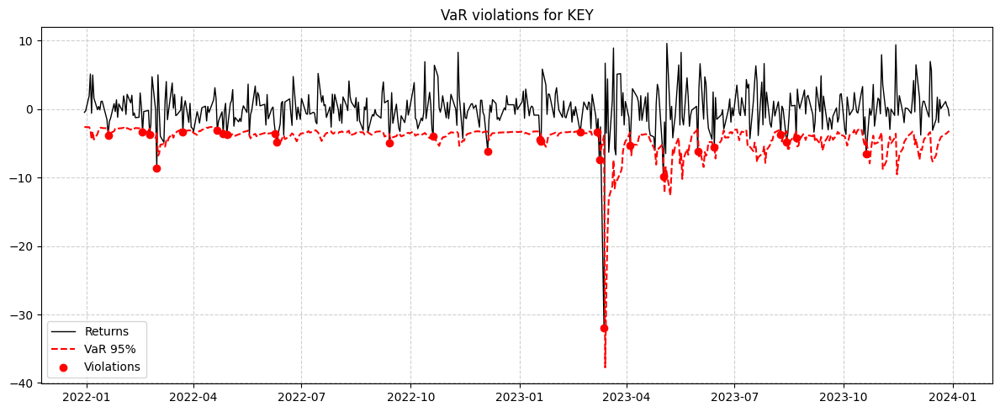

Number of violations: 27 over 503 days → about 5.37% of cases.
If the model is well calibrated this proportion should be close to 5%.


In [25]:
# Intuition: Check how often the VaR is violated
alpha = 0.05
asset = df_ret_asset_bt.columns[7]
returns = df_ret_asset_bt[asset]
VaR = df_VaR_asset_bt[asset]

violations = (returns < VaR).astype(int)

violation_rate = violations.mean()
print(f"Empirical violation rate for {asset}: {violation_rate:.3%} (expected {alpha:.0%})")


plt.figure(figsize=(12, 5))
plt.plot(returns, label='Returns', color='black', linewidth=1)
plt.plot(VaR, label=f'VaR {int((1-alpha)*100)}%', color='red', linestyle='--')
plt.scatter(returns.index[violations == 1], returns[violations == 1], 
            color='red', label='Violations', zorder=5)
plt.title(f"VaR violations for {asset}")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

n_viol = violations.sum()
n_total = len(violations)
print(f"Number of violations: {n_viol} over {n_total} days → about {100*violation_rate:.2f}% of cases.")
print("If the model is well calibrated this proportion should be close to 5%.")


In [26]:
alpha = 0.05
violation_summary = pd.DataFrame(columns=["Violations", "Total Obs", "Violation Rate (%)"])

for asset in df_ret_asset_bt.columns:
    returns = df_ret_asset_bt[asset]
    VaR = df_VaR_asset_bt[asset]

    violations = (returns < VaR).astype(int)
    n_viol = violations.sum()
    n_total = len(violations)
    violation_rate = 100 * n_viol / n_total

    violation_summary.loc[asset] = [n_viol, n_total, round(violation_rate, 2)]

print("\n--- VaR Violation Summary across assets ---")
display(violation_summary)

mean_rate = violation_summary["Violation Rate (%)"].mean()
print(f"\nAverage violation rate across assets: {mean_rate:.2f}% (expected {alpha*100:.0f}%)")



--- VaR Violation Summary across assets ---


,Violations,Total Obs,Violation Rate (%)
ALL,28.0,503.0,5.57
PNC,30.0,503.0,5.96
MBI,30.0,503.0,5.96
AIG,31.0,503.0,6.16
HIG,30.0,503.0,5.96
UNM,18.0,503.0,3.58
HUM,33.0,503.0,6.56
KEY,27.0,503.0,5.37
CINF,23.0,503.0,4.57
GS,24.0,503.0,4.77



Average violation rate across assets: 5.14% (expected 5%)


In [27]:
from scipy.stats import chi2

### Unconditional coverage test

Kupiec (1995) introduced a variation on the binomial test called the proportion of failures (POF) test.  
The POF test works with the binomial distribution approach. In addition, it uses a likelihood ratio to test whether the probability of exceptions is synchronized with the probability \(p\) implied by the VaR confidence level.  
If the data suggests that the probability of exceptions is different than \(p\), the VaR model is rejected.  

The POF test statistic is

$$
LR_{POF} = -2 \log \left( \frac{(1-p)^{N-x} p^x}{\left(1-\frac{x}{N}\right)^{N-x} \left(\frac{x}{N}\right)^x} \right)
$$

where \(x\) is the number of failures, \(N\) the number of observations and \(p = VaR level\).  

This statistic is asymptotically distributed as a chi-square variable with 1 degree of freedom.  
The VaR model fails the test if this likelihood ratio exceeds a critical value.  
The critical value depends on the test confidence level.

### Independence test

Christoffersen (1998) proposed a test to measure whether the probability of observing an exception on a particular day depends on whether an exception occurred.  
Unlike the unconditional probability of observing an exception, Christoffersen's test measures the dependency between consecutive days only.  
The test statistic for independence in Christoffersen’s interval forecast (IF) approach is given by:

$$
LR_{CCI} = -2 \log \left( 
\frac{(1 - \pi)^{n00+n10} \pi^{n01+n11}}
{(1 - \pi_0)^{n00} \pi_0^{n01} (1 - \pi_1)^{n10} \pi_1^{n11}} 
\right)
$$

where

- \(n00\) = Number of periods with no failures followed by a period with no failures.  
- \(n10\) = Number of periods with failures followed by a period with no failures.  
- \(n01\) = Number of periods with no failures followed by a period with failures.  
- \(n11\) = Number of periods with failures followed by a period with failures.  

and

- $\pi_0$ — Probability of having a failure on period \(t\), given that no failure occurred on period \(t-1\):  
$$
  \pi_0 = \frac{n01}{n00 + n01}
$$

- $\pi_1$ — Probability of having a failure on period \(t\), given that a failure occurred on period \(t-1\):  
  $$
  \pi_1 = \frac{n11}{n10 + n11}
  $$

- $\pi$ — Probability of having a failure on period \(t\):  
  $$
  \pi = \frac{n01 + n11}{n00 + n01 + n10 + n11}
  $$


This statistic is asymptotically distributed as a chi-square variable with 1 degree of freedom.  


### CC test

Christoffersen (1998) also proposed the **Conditional Coverage (CC) test**, which jointly evaluates whether the frequency of exceptions is correct (Unconditional Coverage, UC) **and** whether exceptions occur independently (Independence, IND).  

The test statistic is simply the sum of the UC and IND likelihood ratio statistics:

$$
LR_{CC} = LR_{UC} + LR_{CCI}
$$


This statistic is asymptotically distributed as a chi-square variable with 2 degrees of freedom.

In [30]:
def coverage_test_log_05(df_returns, df_VaR, alpha=0.05, test_alpha=0.05):
    results_list = []
    eps = 1e-12  # small epsilon to avoid log(0) / division by zero

    for col_name in df_VaR.columns:
        print(f"\nResults of {col_name}:")
        # Merge/align returns and VaR on the same date index.
        df_test = pd.merge(pd.DataFrame(df_returns[col_name]).reset_index(),pd.DataFrame(df_VaR[col_name].dropna()).reset_index(),
            on="Date", how="inner").set_index("Date")
        # Extract the aligned return series and VaR series
        returns = df_test.iloc[:, 0].astype(float)
        var_series = df_test.iloc[:, 1].astype(float)

        #  Build the Exception indicator I_t = 1{ r_t < VaR_t } and drop NaN.
        I = (returns < var_series).astype(int)
        I = I.dropna()
        T = len(I)

        # ---------- UC (Kupiec) ----------
        # Count violations and non-violations
        n_1 = int(I.sum())
        n_0 = T - n_1
        pi_hat_uc = n_1 / T 

        # Guard against log(0) by clipping probabilities with eps.
        a0 = max(1 - alpha, eps)
        a1 = max(alpha, eps)
        p0 = max(1 - pi_hat_uc, eps)
        p1 = max(pi_hat_uc, eps)
        # UC likelihoods
        log_L_uc_H0 = n_0 * np.log(a0) + n_1 * np.log(a1) #leveraging on log properties ln(a/b) = ln(a)-ln(b), ln(a^x) = xln(a) ... 
        log_L_uc_H1 = n_0 * np.log(p0) + n_1 * np.log(p1)
        # UC LR stat and p-value
        LR_uc = -2 * (log_L_uc_H0 - log_L_uc_H1) # building the full statistic 
        Pvalue_uc = 1 - chi2.cdf(LR_uc, 1)

        # ---------- Ind (Christoffersen independence) ----------
        # Build lag/lead of I_t to count transitions n_00, n_01, n_10, n_11
        I_lag = I.iloc[:-1].values
        I_lead = I.iloc[1:].values
        n_00 = int(((I_lag == 0) & (I_lead == 0)).sum())
        n_01 = int(((I_lag == 0) & (I_lead == 1)).sum())
        n_10 = int(((I_lag == 1) & (I_lead == 0)).sum())
        n_11 = int(((I_lag == 1) & (I_lead == 1)).sum())
        
        # Denominators and totals for transition probabilities.
        denom0 = n_00 + n_01
        denom1 = n_10 + n_11
        total  = n_00 + n_01 + n_10 + n_11

        # H0 overall failure prob and H1 transition probs
        pi_hat_ind = (n_01 + n_11) / total 
        pi_hat_01 = n_01 / denom0 
        pi_hat_11 = n_11 / denom1 

        # Guard logs for Ind part
        pi = max(1 - pi_hat_ind, eps)
        pi_barre = max(pi_hat_ind, eps)
        r00 = max(1 - pi_hat_01, eps)
        r01 = max(pi_hat_01, eps)
        r10 = max(1 - pi_hat_11, eps)
        r11 = max(pi_hat_11, eps)
        # Ind likelihoods
        log_L_ind_H0 = (n_00 + n_10) * np.log(pi) + (n_01 + n_11) * np.log(pi_barre)
        log_L_ind_H1 = n_00 * np.log(r00) + n_01 * np.log(r01) + n_10 * np.log(r10) + n_11 * np.log(r11)
        # Ind LR stat and p-value
        LR_ind = -2 * (log_L_ind_H0 - log_L_ind_H1)
        Pvalue_ind = 1 - chi2.cdf(LR_ind, 1)

        # ---------- CC (Christoffersen conditional coverage) ----------
        
        LR_cc = LR_uc + LR_ind
        Pvalue_cc = 1 - chi2.cdf(LR_cc, 2)

        print(f"UC test:  LR = {LR_uc:.4f}, p-value = {Pvalue_uc:.4f}")
        print(f"Ind test: LR = {LR_ind:.4f}, p-value = {Pvalue_ind:.4f}")
        print(f"CC test:  LR = {LR_cc:.4f}, p-value = {Pvalue_cc:.4f}")

        results_list.append([col_name, Pvalue_uc, Pvalue_ind, Pvalue_cc])

    df_results = pd.DataFrame(results_list, columns=["Company", "UC p-value", "Ind p-value", "CC p-value"])

    df_summary = pd.DataFrame({
        f"p < {test_alpha}": [
            np.sum(df_results["UC p-value"]  < test_alpha),
            np.sum(df_results["Ind p-value"] < test_alpha),
            np.sum(df_results["CC p-value"]  < test_alpha)
        ],
        f"p ≥ {test_alpha}": [
            np.sum(df_results["UC p-value"]  >= test_alpha),
            np.sum(df_results["Ind p-value"] >= test_alpha),
            np.sum(df_results["CC p-value"]  >= test_alpha)
        ],
        "NaN": [
            np.sum(df_results["UC p-value"].isna()),
            np.sum(df_results["Ind p-value"].isna()),
            np.sum(df_results["CC p-value"].isna())
        ]
    }, index=["UC", "Ind", "CC"])

    df_reject = pd.DataFrame({
        f"Reject (<{test_alpha})": [
            df_results.loc[df_results["UC p-value"]  < test_alpha, "Company"].tolist(),
            df_results.loc[df_results["Ind p-value"] < test_alpha, "Company"].tolist(),
            df_results.loc[df_results["CC p-value"]  < test_alpha, "Company"].tolist()
        ]
    }, index=["UC", "Ind", "CC"])

    return df_results, df_summary, df_reject

In [29]:
df_results_05, df_summary_05, df_reject_05 = coverage_test_log_05(df_ret_asset_bt, df_VaR_asset_bt, alpha=0.05, test_alpha = 0.05)
print(df_summary_05)


Results of ALL:
UC test:  LR = 0.3284, p-value = 0.5666
Ind test: LR = 0.1279, p-value = 0.7206
CC test:  LR = 0.4563, p-value = 0.7960

Results of PNC:
UC test:  LR = 0.9298, p-value = 0.3349
Ind test: LR = 0.4636, p-value = 0.4959
CC test:  LR = 1.3934, p-value = 0.4982

Results of MBI:
UC test:  LR = 0.9298, p-value = 0.3349
Ind test: LR = 0.4636, p-value = 0.4959
CC test:  LR = 1.3934, p-value = 0.4982

Results of AIG:
UC test:  LR = 1.3379, p-value = 0.2474
Ind test: LR = 2.0404, p-value = 0.1532
CC test:  LR = 3.3783, p-value = 0.1847

Results of HIG:
UC test:  LR = 0.9298, p-value = 0.3349
Ind test: LR = 0.7827, p-value = 0.3763
CC test:  LR = 1.7124, p-value = 0.4248

Results of UNM:
UC test:  LR = 2.3650, p-value = 0.1241
Ind test: LR = 9.2977, p-value = 0.0023
CC test:  LR = 11.6626, p-value = 0.0029

Results of HUM:
UC test:  LR = 2.3585, p-value = 0.1246
Ind test: LR = 0.0155, p-value = 0.9009
CC test:  LR = 2.3740, p-value = 0.3051

Results of KEY:
UC test:  LR = 0.1400, 

The UC test is successfull for all the 20 companies

The Ind test is however successfull for 18 companies

The CC Test is successfull for 19 companies 

In [31]:
print(df_reject_05)

    Reject (<0.05)
UC              []
Ind     [UNM, UNH]
CC           [UNM]


UNM and UNH don't pass the Ind test while UNM doesn't pass the CC test

## CoVaR (Adrian and Brunnermeier, 2014)

The **CoVaR** is the Value-at-Risk of the market return given a specific event on the firm return:

$$
\Pr\left( r_{mt} \leq CoVaR_{t}^{m \mid r_{it} = VaR_{it}(\alpha)} \ \big|\ r_{it} = VaR_{it}(\alpha) \right) = \alpha.
$$


## ΔCoVaR

The contribution of the institution to systemic risk, **ΔCoVaR**, is the difference between its CoVaR and the CoVaR calculated at the median state:

$$
\Delta CoVaR_{it}(\alpha) = CoVaR_{t}^{m \mid r_{it} = VaR_{it}(\alpha)} - CoVaR_{t}^{m \mid r_{it} = Median(r_{it})}.
$$

---



Under the **Gaussian linear assumption**, the ΔCoVaR can be written as:

$$
\Delta CoVaR_{\alpha}^{m \mid i,t+1} 
= \rho_{m,i,t+1} \times \frac{\sigma_{m,t+1}}{\sigma_{i,t+1}} \times 
\Big( VaR_{\alpha}^{i,t+1} - \text{Median}(r_{i,t}) \Big).
$$

In [32]:
# Market return
df_ret_mkt = pd.read_csv('ret_mkt.csv')
df_ret_mkt['Date'] = pd.to_datetime(df_ret_mkt['Date'])
df_ret_mkt.set_index('Date', inplace = True)
df_ret_mkt

,Return_mkt
Date,
2021-01-04,-1.292168
2021-01-05,0.255675
2021-01-06,4.277497
2021-01-07,1.673655
2021-01-08,-0.141270
...,...
2023-12-22,0.262737
2023-12-26,0.433775
2023-12-27,0.283583


In [33]:
# Calculate the market predicted volatility using function compute_var()
df_VaR_mkt, df_Vol_mkt, df_Q05_mkt = compute_var(df_ret_mkt)

[1.41353249 1.32413371 1.15911636 2.04993291 1.78522792 1.46414069
 1.25158669 1.15236288 1.04815374 0.98336346 1.15261994 1.05808922
 0.99420756 0.98954193 1.03027797 1.01135499 1.03478476 1.62496538
 1.58703135 1.5760214  1.37300754 1.5572493  1.32048825 1.34653795
 1.17038037 1.12938072 1.03546124 0.97432808 0.93780401 0.95284779
 1.07689556 1.00989177 0.96552518 0.98915417 1.07884415 1.06451072
 1.32230256 1.39624047 1.36004865 1.64757554 1.36977612 1.22713328
 1.1767754  1.36197325 1.31666755 1.17701188 1.27079417 1.12004498
 1.12152333 1.04567268 1.04572538 0.99522986 0.99874472 1.05359433
 1.09214178 1.14704034 1.06620755 1.15228103 1.25178089 1.16287541
 1.07384981 1.0643838  1.07069939 1.04112704 0.98371426 0.96266944
 0.93120075 1.02142874 0.97231185 1.00936619 1.00159519 0.96816897
 0.95552863 0.9301529  1.11684527 1.15929341 1.13477082 1.22884788
 1.09902695 1.06029219 1.00061175 1.12541895 1.12126572 1.0536594
 1.02772435 1.01066796 1.11927185 1.04554317 0.98126946 1.13232

In [34]:
df_Vol_mkt

,Return_mkt
Date,
2021-01-04,NaN
2021-01-05,NaN
2021-01-06,NaN
2021-01-07,NaN
2021-01-08,NaN
...,...
2023-12-22,1.000242
2023-12-26,0.915506
2023-12-27,0.869101


# $\rho$ in DCC(1,1): Engle (2002) Dynamic Conditional Correlation

This is the first time you see a **multivariate** GARCH model, so before jumping into formulas, here is the
intuition. Earlier in this notebook you built, for a *single* return series, a GARCH(1,1) forecast of its
conditional variance $h_t$ (function `compute_var`). The DCC model simply asks the same kind of question, but
for the **correlation between two (or more) series**: instead of assuming the correlation between the asset
return and the market return is constant over time, we let it move, with its own GARCH-like recursion. This is
exactly the $\rho_{m,i,t+1}$ that appears in the $\Delta CoVaR$ formula above — so this section is the "missing
ingredient" needed to compute $\Delta CoVaR$ under the Gaussian assumption.

The idea, due to Engle (2002), is to **split the problem in two steps**:

1. **Volatility step** — fit a univariate GARCH(1,1) to *each* series separately (exactly like `compute_var`
   does), to get each series' own conditional variance $h_{it}$.
2. **Correlation step** — standardize each series by its own volatility, and fit a *second*, small GARCH-type
   model, not to the variances, but to the time-varying **correlation matrix** of the standardized series.

Steps 1) to 5) below formalize step 2. Section 6) explains how the parameters are estimated, and section 7)
summarizes, as a checklist, what you would actually need to code to reproduce the `DCC_Rho.csv` column by
yourself.

---

## 1) Covariance–correlation decomposition
Let $H_t$ be the $N\times N$ **conditional covariance** matrix of returns $\varepsilon_t$ (innovations, i.e. the
return minus its conditional mean — here the mean is simply set to $0$, as in the `ugarchspec` used in the R
script). Any covariance matrix can be decomposed into volatilities and a correlation matrix, exactly like the
scalar identity $\text{cov}(x,y)=\sigma_x\sigma_y\,\rho_{xy}$, but written for the whole matrix at once:
$$
H_t = D_t\, R_t\, D_t,
$$
where $D_t=\mathrm{diag}\big(\sqrt{h_{1t}},\ldots,\sqrt{h_{Nt}}\big)$ is a *diagonal* matrix collecting the
**univariate conditional volatilities** (one GARCH(1,1) per series — this is exactly what `compute_var` already
gives you for the asset and for the market), and $R_t$ is the $N\times N$ **time-varying correlation matrix**
we are after (for us, $N=2$: the asset and the market).

Nothing here is new or model-specific: this decomposition is an identity that holds for *any* covariance matrix.
The DCC model is the specific way of making $R_t$ **time-varying** that is described next.

---

## 2) Standardized residuals
Define standardized residuals
$$
u_t = D_t^{-1}\varepsilon_t = \big(u_{1t},\ldots,u_{Nt}\big)^\top,
\qquad u_{it}=\frac{\varepsilon_{it}}{\sqrt{h_{it}}}.
$$
In words: take the return of each series and divide it by its *own* GARCH volatility at time $t$. By
construction each $u_{it}$ has (approximately) unit conditional variance, so **all of each series' own
volatility dynamics have been removed**. Whatever structure is *left* in the comovement of $u_{1t}$ and $u_{2t}$
is genuinely about correlation, not about one series being more volatile than the other.

Let $\bar Q=\mathbb{E}[u_tu_t^\top]$ denote the **unconditional covariance** of $u_t$ (in practice, estimated by
the sample covariance of the standardized residuals over the estimation window). Because the $u_{it}$ are
standardized, $\bar Q$ is also approximately a correlation matrix (unit diagonal), and it plays the role of the
**long-run ("steady state") target** that the time-varying correlation reverts to — the same role that the
long-run variance plays in a univariate GARCH(1,1). We assume $\bar Q$ is positive definite.

---

## 3) DCC(1,1) dynamics (Engle, 2002)
We now want a *time-varying* analogue of $\bar Q$. Introduce an auxiliary $N\times N$ symmetric positive
definite matrix $Q_t$ that follows a GARCH-type recursion — literally a GARCH(1,1) recursion, but applied to a
matrix instead of a scalar variance:
$$
\boxed{\quad
Q_t=(1-\alpha-\beta)\,\bar Q\;+\;\alpha\,u_{t-1}u_{t-1}^\top\;+\;\beta\,Q_{t-1},
\quad \alpha\ge 0,\;\beta\ge 0,\;\alpha+\beta<1.
\quad}
$$
Each term has the same interpretation as in a univariate GARCH(1,1) variance equation:
- $(1-\alpha-\beta)\bar Q$ is the pull back towards the **long-run level** $\bar Q$ (the "intercept"),
- $\alpha\,u_{t-1}u_{t-1}^\top$ is the **reaction to the latest shock**: if the asset and the market moved
  together yesterday (same sign, large magnitude), this term pushes correlation up today,
- $\beta\,Q_{t-1}$ is the **persistence** term: correlation does not jump around, it inherits most of its level
  from the previous period.

The constraints $\alpha,\beta\ge 0$ and $\alpha+\beta<1$ play exactly the same role as in univariate
GARCH(1,1): they guarantee $Q_t$ stays positive definite and that the recursion is **mean-reverting** to
$\bar Q$ rather than exploding or drifting to a degenerate matrix.

One subtlety: $Q_t$ itself is **not** a correlation matrix — its diagonal elements $q_{ii,t}$ are not
necessarily equal to $1$ (the recursion mixes a correlation-like matrix $\bar Q$ with outer products
$u_{t-1}u_{t-1}^\top$ that need not have unit diagonal either). This is why there is one more step, called
**correlation targeting**: rescale $Q_t$ so that its diagonal is exactly $1$, which gives the actual dynamic
correlation matrix:
$$
\boxed{\quad
R_t = \mathrm{diag}(Q_t)^{-1/2}\; Q_t\; \mathrm{diag}(Q_t)^{-1/2}.
\quad}
$$
($\mathrm{diag}(Q_t)^{-1/2}$ is the diagonal matrix of $1/\sqrt{q_{ii,t}}$.) This normalization is exactly the
matrix version of turning a covariance into a correlation: $\rho_{xy}=\text{cov}(x,y)/(\sigma_x\sigma_y)$.

---

## 4) Pairwise correlation coefficient $\rho_{ij,t}$
Let $q_{ij,t}$ denote the $(i,j)$ element of $Q_t$. Reading off the $(i,j)$ entry of the normalization above
gives the DCC correlation between series $i$ and $j$:
$$
\boxed{\quad
\rho_{ij,t}=\frac{q_{ij,t}}{\sqrt{q_{ii,t}\,q_{jj,t}}}.
\quad}
$$
This is simply "covariance over the square root of the product of variances", applied to the elements of
$Q_t$ instead of $H_t$ — the same identity as in step 1), one level down.

---

## 5) Bivariate explicit formula
Here $N=2$: series $1$ is the **asset** return and series $2$ is the **market** return, so
$\rho_{12,t}$ below is exactly the $\rho_{m,i,t}$ used later in the $\Delta CoVaR$ formula. Write
$\bar Q=\begin{pmatrix}\bar q_{11}&\bar q_{12}\\ \bar q_{12}&\bar q_{22}\end{pmatrix}$ for the long-run
covariance of the standardized residuals. Writing out the recursion of step 3) element by element:
$$
\begin{aligned}
q_{12,t} &= (1-\alpha-\beta)\,\bar q_{12} + \alpha\,u_{1,t-1}u_{2,t-1} + \beta\,q_{12,t-1},\\[2pt]
q_{11,t} &= (1-\alpha-\beta)\,\bar q_{11} + \alpha\,u_{1,t-1}^2       + \beta\,q_{11,t-1},\\[2pt]
q_{22,t} &= (1-\alpha-\beta)\,\bar q_{22} + \alpha\,u_{2,t-1}^2       + \beta\,q_{22,t-1}.
\end{aligned}
$$
Hence the DCC(1,1) correlation is
$$
\boxed{\quad
\rho_{12,t}
=\frac{(1-\alpha-\beta)\,\bar q_{12}+\alpha\,u_{1,t-1}u_{2,t-1}+\beta\,q_{12,t-1}}
{\sqrt{\Big((1-\alpha-\beta)\,\bar q_{11}+\alpha\,u_{1,t-1}^2+\beta\,q_{11,t-1}\Big)
      \Big((1-\alpha-\beta)\,\bar q_{22}+\alpha\,u_{2,t-1}^2+\beta\,q_{22,t-1}\Big)}}.
\quad}
$$
Everything on the right-hand side is known once you know $\alpha$, $\beta$, $\bar Q$, and the history of
standardized residuals $u_{1,\cdot}$, $u_{2,\cdot}$ up to $t-1$ — which is exactly what step 6) below estimates.

---

## 6) Where do $\alpha$, $\beta$, and $\bar Q$ come from? (Engle's two-step QMLE)
The formula above assumes $\alpha$, $\beta$ and $\bar Q$ are known, but in practice they must be **estimated**
from the data. Engle (2002) proposes a convenient **two-step quasi maximum likelihood** procedure that avoids
estimating everything at once:

- **Step A (univariate):** fit a GARCH(1,1) separately to the asset return and to the market return (same as
  `compute_var`), which gives $h_{1t}$, $h_{2t}$ and hence the standardized residuals $u_{1t}$, $u_{2t}$.
- **Step B (correlation):** set $\bar Q$ to the sample covariance matrix of $(u_{1t},u_{2t})$ over the
  estimation window, then choose $\alpha,\beta$ by maximizing the "correlation part" of the Gaussian
  log-likelihood,
  $$
  \mathcal{L}(\alpha,\beta) = -\frac{1}{2}\sum_t \Big[\log|R_t| + u_t^\top R_t^{-1} u_t - u_t^\top u_t\Big],
  $$
  where $R_t$ is built from $\alpha,\beta,\bar Q$ through the recursion of steps 3)–4) above, *given* the
  $u_t$'s from step A. This is a numerical optimization over two scalars $(\alpha,\beta)$ with the constraints
  $\alpha,\beta\ge 0,\ \alpha+\beta<1$ — much cheaper than estimating all parameters of a full multivariate
  GARCH jointly, which is the whole point of Engle's "two-step" trick.

In the R script (next cell), this is exactly what `dccfit()` does internally (with a Student-$t$ instead of
Gaussian distribution), and `dccforecast()` plugs the fitted $\alpha,\beta,\bar Q$ and the last observed $u_t$'s
into the recursion once more to get the **one-step-ahead** forecast $R_{t+1\mid t}$, from which
$\rho_{m,i,t+1}=\rho_{12,t+1\mid t}$ is read off.

---

## 7) What to actually code: a checklist
Putting steps 1)–6) together, reproducing one column of `DCC_Rho.csv` for a given asset means, for every day
$t$ in a rolling window of (here) 250 observations:

1. Take the pair (asset return, market return) over the trailing window.
2. Fit a GARCH(1,1) to each of the two series (mean $=0$) $\Rightarrow$ get $h_{1t},h_{2t}$ and standardized
   residuals $u_{1t}=\varepsilon_{1t}/\sqrt{h_{1t}}$, $u_{2t}=\varepsilon_{2t}/\sqrt{h_{2t}}$ for every day in
   the window.
3. Compute $\bar Q$ = sample covariance matrix of $(u_{1t},u_{2t})$ over the window.
4. Estimate $(\alpha,\beta)$ by maximizing the correlation log-likelihood of step 6) B, given $\bar Q$ and the
   $u_t$'s.
5. Run the recursion of step 3) forward through the window to get the last in-sample $Q_T$, then take **one
   more step** with the last $u_T$ to obtain the one-step-ahead forecast $Q_{T+1\mid T}$ (same recursion,
   evaluated once more).
6. Normalize $Q_{T+1\mid T}$ as in step 4) to get $\rho_{12,T+1\mid T}$ — this single number is what gets
   written into `DCC_Rho.csv` for day $T+1$ and that asset.
7. Slide the window forward by one day and repeat (this is why the R function is a loop over `j` that refits
   the whole model at every step — exactly like a rolling VaR backtest, except here the whole model is
   re-estimated at each step rather than only the forecast being recomputed).

This is computationally heavy (one full DCC re-estimation **per day, per asset**), which is precisely why it
was done once in R and the result saved to `DCC_Rho.csv`, instead of being recomputed every time this notebook
runs.


The multivariate GARCH (MGARCH) ecosystem in Python is much less mature than in R: there is no
Python package that matches `rmgarch`'s `dccfit`/`dccforecast` convenience (joint handling of the univariate
step, the correlation step, multivariate-$t$ innovations, forecasting, standard errors, etc.), so for this
illustration we ran the two-step procedure of section 6)–7) above in R (script `DCC in R.R`) and simply load
its output below. Nothing here is specific to R, though: everything described above (fit two GARCH(1,1)'s,
build $\bar Q$, estimate $\alpha,\beta$ by maximizing $\mathcal{L}(\alpha,\beta)$, iterate the recursion) can be
coded by hand in Python with `arch` (for the univariate GARCH step) plus `numpy`/`scipy.optimize` (for the
correlation step) — it is just not available as a single ready-made function the way it is in R.

In [3]:
df_Rho = pd.read_csv('DCC_Rho.csv')
df_Rho['Date'] = pd.to_datetime(df_Rho['Date'])
df_Rho.set_index('Date', inplace = True)
df_Rho

,ALL,PNC,MBI,AIG,HIG,UNM,HUM,KEY,CINF,GS,UNH,BK,NTRS,PGR,AXP,SEIC,FITB,ZION,CNA,BEN
Date,,,,,,,,,,,,,,,,,,,,
2021-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,0.475766,0.846767,0.156748,0.684265,0.660077,0.393421,0.245267,0.706959,0.576749,0.717409,0.344079,0.801277,0.834009,0.354048,0.780077,0.717005,0.777542,0.711914,0.335541,0.696977
2023-12-26,0.481583,0.788644,NaN,0.690073,0.660041,0.406576,0.244916,0.706761,0.575746,0.716216,0.343258,0.764090,0.808932,0.341799,0.757391,0.721823,0.777897,0.710428,0.364455,0.692642
2023-12-27,0.490606,0.782244,0.161043,0.695064,0.660478,0.422486,0.244987,0.711873,0.575457,0.715320,0.343200,0.764423,0.791080,0.296407,0.732103,0.710866,0.778555,0.712069,0.379961,0.694516


### Can this be done natively in Python? — calling R's `rmgarch` via `rpy2`

Short answer: **yes**. Python has no package as complete as `rmgarch` (univariate step + DCC step + forecasting
+ multivariate-$t$, all in one API), but [`rpy2`](https://rpy2.github.io/) lets a Python process start a real R
session in-process and call `rugarch`/`rmgarch` functions directly, passing data back and forth as
NumPy/pandas objects. No separate `.R` script, no manual CSV hand-off: everything below runs from this
notebook, in Python, and only *delegates the model fitting itself* to R's (more mature) GARCH engine.

**One-time setup** (skip if already installed):
```bash
pip install rpy2
```
```r
install.packages(c("rugarch", "rmgarch"))   # run inside R, once
```
You also need a working R installation on the machine (R itself, not just the packages); `rpy2` talks to it
through `R_HOME`.

Below, we rebuild *exactly* the same `uspec`/`mspec`/`dccspec` objects as in `DCC in R.R`, but by calling the R
functions from Python, and we check the forecasted $\rho_{m,i,t+1}$ we get this way against the cached
`DCC_Rho.csv` column for the same asset — they should match to numerical precision (the model, the data and the
optimizer are literally the same; only the "calling language" differs).

**Why we don't just rerun the *whole* rolling backtest here:** each `dccfit`+`dccforecast` call refits a full
DCC(1,1) model on 250 observations, which takes roughly 1 second. The full backtest in `DCC in R.R` repeats this
for every trading day **and** every one of the 20 assets (about $503\times20\approx10{,}000$ fits), i.e. several
hours — which is exactly why it was run once (in R, but the same would be true in Python) and cached to
`DCC_Rho.csv` instead of being recomputed on every notebook run. Below we only run a handful of rolling steps,
for one asset, as a proof that the Python/`rpy2` route reproduces the cached R results.

In [ ]:
import os
import glob

# Point rpy2 to your R installation. If R_HOME is already set in your environment this is a no-op;
# otherwise we try to auto-detect a Windows R install (adjust the pattern/path if yours differs).
if not os.environ.get("R_HOME"):
    candidates = sorted(glob.glob(r"C:\Program Files\R\R-*"))
    if candidates:
        os.environ["R_HOME"] = candidates[-1]

if os.environ.get("R_HOME"):
    bin_dir = os.path.join(os.environ["R_HOME"], "bin", "x64")
    if not os.path.isdir(bin_dir):
        bin_dir = os.path.join(os.environ["R_HOME"], "bin")
    os.environ["PATH"] = bin_dir + os.pathsep + os.environ["PATH"]

import numpy as np
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.packages import importr

pandas2ri.activate()
numpy2ri.activate()

base = importr("base")
rugarch = importr("rugarch")
rmgarch = importr("rmgarch")

# Same univariate margins as in DCC in R.R: sGARCH(1,1), mean = 0, normal innovations.
uni_spec = rugarch.ugarchspec(
    **{
        "variance.model": ro.ListVector({"model": "sGARCH", "garchOrder": ro.IntVector([1, 1])}),
        "mean.model": ro.ListVector({"armaOrder": ro.IntVector([0, 0]), "include.mean": False}),
        "distribution.model": "norm",
    }
)
mspec = rugarch.multispec(base.replicate(2, uni_spec))

# Same DCC(1,1) spec, multivariate-t distribution.
dcc_spec = rmgarch.dccspec(uspec=mspec, dccOrder=ro.IntVector([1, 1]), distribution="mvt")

# Pulls out the 2x2 forecasted covariance matrix H_{t+1|t} from a dccforecast object.
extract_H = ro.r("function(fcast) fcast@mforecast$H[[1]][,,1]")

In [ ]:
def dcc_rho_rpy2(asset_series, mkt_series, dates, window=250, n_steps=None):
    # Rolling one-step-ahead DCC(1,1) correlation forecast, mirroring cal_rho() in DCC in R.R.
    # For each day, refit the DCC model on the trailing `window` observations and forecast rho
    # one step ahead (section 7 of the DCC markdown cell above). n_steps caps how many rolling
    # forecasts are computed (each one costs ~1 second); leave it unset only if you are prepared
    # to wait for the full series.
    n = len(asset_series)
    last_j = (n - 1) if n_steps is None else min(window + n_steps, n) - 1

    out_dates, out_rho = [], []
    for j in range(window, last_j + 1):
        data_matrix = np.column_stack([asset_series[j - window:j], mkt_series[j - window:j]])
        r_matrix = ro.r.matrix(ro.FloatVector(data_matrix.flatten(order="F")), nrow=window, ncol=2)

        fit = rmgarch.dccfit(dcc_spec, data=r_matrix)
        fcast = rmgarch.dccforecast(fit, n_ahead=1, n_roll=0)
        Hf = np.array(extract_H(fcast))

        rho_forecast = Hf[0, 1] / np.sqrt(Hf[0, 0] * Hf[1, 1])
        out_dates.append(dates[j])
        out_rho.append(rho_forecast)

    return pd.Series(out_rho, index=pd.to_datetime(out_dates), name="rho_rpy2")

In [ ]:
# Proof of equivalence: recompute the first 15 rolling forecasts for one asset in pure Python
# (via rpy2) and compare them to the R-produced, cached column in df_Rho.
asset_col = "ALL"

rho_from_python = dcc_rho_rpy2(
    df_ret_asset[asset_col].values,
    df_ret_mkt["Return_mkt"].values,
    df_ret_asset.index.values,
    window=250,
    n_steps=15,
)

compare = pd.DataFrame({
    "rho_python_rpy2": rho_from_python,
    "rho_R_cached": df_Rho.loc[rho_from_python.index, asset_col],
})
compare["abs_diff"] = (compare["rho_python_rpy2"] - compare["rho_R_cached"]).abs()
compare

In [ ]:
# Now calculate the Delta CoVaR as in the equation
df_DCoVaR = pd.DataFrame(index=df_Rho.index, columns=df_Rho.columns)
for column in df_Rho.columns:
    combined_df = pd.concat([df_Rho[column], df_Vol_mkt['Return_mkt'], df_Vol_asset[column], df_VaR_asset[column]], 
                            axis=1, join='inner')
    combined_df.columns = ['rho_mi_t', 'sigma_mt1', 'sigma_it1', 'VaR_it1']

    DCoVaR_it = (combined_df['rho_mi_t'] * 
                 (combined_df['sigma_mt1'] / combined_df['sigma_it1']) * 
                  combined_df['VaR_it1']) 
    # We neglect the median since the gaussian assumption make it null, without assumption this is usually close to 0
    df_DCoVaR.loc[DCoVaR_it.index, column] = DCoVaR_it 

In [ ]:
df_DCoVaR